In [8]:
import pandas as pd

cycle_summary = pd.read_csv(
    r"C:\Users\suman\Documents\meatech-battery-analytics-case-study\data\processed\cycle_summary.csv"
)

cycle_summary[["run_id", "Cycle_Index", "discharge_capacity_ah"]].head()

,run_id,Cycle_Index,discharge_capacity_ah
0,LR1865SZ_cycles201217_001_2,1,2.271
1,LR1865SZ_cycles201217_001_2,2,1.512
2,LR1865SZ_cycles201217_001_2,3,1.457
3,LR1865SZ_cycles201217_001_2,4,1.418
4,LR1865SZ_cycles201217_001_2,5,1.411


In [12]:
rows = cycle_summary.loc[
    (cycle_summary["run_id"] == "LR1865SZ_cycles201214_002_4")
    & cycle_summary["Cycle_Index"].between(90, 92),
    ["Cycle_Index", "discharge_capacity_ah"],
]
display(rows.sort_values("Cycle_Index"))

,Cycle_Index,discharge_capacity_ah
190,90,0.504
191,91,0.501
192,92,0.491


Calculate the deviation for each cycle.

In [9]:
capacity = cycles_summary.groupby("run_id")["discharge_capacity_ah"]
previous = capacity.shift(1)
following = capacity.shift(-1)

cycles["expected_ah"] = (previous + following) / 2
cycles["deviation_ah"] = cycles["discharge_capacity_ah"] - cycles["expected_ah"]

cycles.loc[cycles["Cycle_Index"].eq(91)].round(4)

,Cycle_Index,run_id,discharge_capacity_ah,expected_ah,deviation_ah
191,91,LR1865SZ_cycles201214_002_4,0.501,0.4975,0.0035
90,91,LR1865SZ_cycles201217_001_2,0.309,0.3100,-0.0010


In [24]:
cycles = cycle_summary.loc[cycle_summary["Cycle_Index"].between(2, 100)].copy()
cycles = cycles.sort_values(["run_id", "Cycle_Index"])

capacity = cycles.groupby("run_id")["discharge_capacity_ah"]
cycles["expected_ah"] = (capacity.shift(1) + capacity.shift(-1)) / 2
cycles["deviation_ah"] = cycles["discharge_capacity_ah"] - cycles["expected_ah"]

display(
    cycles.loc[
        cycles["run_id"].eq("LR1865SZ_cycles201214_002_4")
        & cycles["Cycle_Index"].eq(91),
        ["Cycle_Index", "discharge_capacity_ah", "expected_ah", "deviation_ah"],
    ].round(4)
)

cycles["abs_deviation_ah"] = cycles["deviation_ah"].abs()

ranked = cycles.sort_values("abs_deviation_ah", ascending=False)
columns = ["run_id", "Cycle_Index", "discharge_capacity_ah", "expected_ah", "deviation_ah"]
display(ranked.groupby("run_id").head(3)[columns].sort_values("run_id", kind="stable").round(4))

,Cycle_Index,discharge_capacity_ah,expected_ah,deviation_ah
191,91,0.501,0.4975,0.0035


,run_id,Cycle_Index,discharge_capacity_ah,expected_ah,deviation_ah
150,LR1865SZ_cycles201214_002_4,50,0.861,0.8530,0.0080
115,LR1865SZ_cycles201214_002_4,15,1.495,1.4880,0.0070
106,LR1865SZ_cycles201214_002_4,6,1.621,1.6140,0.0070
7,LR1865SZ_cycles201217_001_2,8,1.333,1.3085,0.0245
4,LR1865SZ_cycles201217_001_2,5,1.411,1.3890,0.0220
8,LR1865SZ_cycles201217_001_2,9,1.276,1.2980,-0.0220


In [14]:
cycles["abs_deviation_mah"] = cycles["abs_deviation_ah"] * 1000
cycles.groupby("run_id")["abs_deviation_mah"].quantile([0.50, 0.95, 1.00]).unstack()

,0.50,0.95,1.00
run_id,,,
LR1865SZ_cycles201214_002_4,1.5,6.1,8.0
LR1865SZ_cycles201217_001_2,2.5,16.6,24.5


In [15]:
# applies each run’s threshold and shows the flagged cycles
limit = cycles.groupby("run_id")["abs_deviation_mah"].transform("quantile", q=0.95)
flagged = cycles.loc[cycles["abs_deviation_mah"] > limit]

display(flagged[["run_id", "Cycle_Index", "deviation_ah", "abs_deviation_mah"]])

,run_id,Cycle_Index,deviation_ah,abs_deviation_mah
106,LR1865SZ_cycles201214_002_4,6,0.0070,7.0
114,LR1865SZ_cycles201214_002_4,14,-0.0065,6.5
115,LR1865SZ_cycles201214_002_4,15,0.0070,7.0
150,LR1865SZ_cycles201214_002_4,50,0.0080,8.0
192,LR1865SZ_cycles201214_002_4,92,-0.0065,6.5
4,LR1865SZ_cycles201217_001_2,5,0.0220,22.0
7,LR1865SZ_cycles201217_001_2,8,0.0245,24.5
8,LR1865SZ_cycles201217_001_2,9,-0.0220,22.0
25,LR1865SZ_cycles201217_001_2,26,0.0170,17.0
26,LR1865SZ_cycles201217_001_2,27,-0.0180,18.0


**Observation:** Five cycles in each run stood out from the local capacity trend. The largest deviation found is at cycle 50 for run1(201214_002_4) with 8mAh more than its neighbors suggested. For run2 cycle 8 delivered 24.5 mAh more than expected, and cycle 9 delivered 22.0 mAh less.

**Inference:** The second run showed larger cycle-to-cycle fluctuations. An 8 mAh deviation was the largest in 201214_002_4, yet it fell below the 16.6 mAh review threshold in 201217_001_2. That’s why it makes sense to judge each cycle against its own run’s behavior. Cycles 8 and 9, and 26 and 27 in run2 looks like a one-cycle swing that bounces back, more like measurement or step-timing noise than degradation.

**Assumptions made:** Over 3 consecutive cycles, capacity normally fades smoothly that the average of the 2 neighbors give a reasnable estimate for the middle cycle. For this the threshold is set for 95th percentile for each run as a practicle review. 

**Limitation:** The threshold picks roughly 5% of the deviations ine ach run, so the flag counts don't tell the equal battery health. Other neighboring cycles contribute to the estimation of deviation hence some cycles worth investigating together, using their voltage and current records. 

### To enhance the analysis add efficiency and voltage deviation

The capacity screen finds cycles that departed from their local capacity trend. To check for unusual behavior across more than one signal, I added coulombic efficiency and average discharge voltage. Average discharge voltage is discharge energy divided by discharge capacity. I compared both features with the average of the previous and next cycle within the same run, using the same idea as the capacity screen.

In [25]:
capacity = cycles["discharge_capacity_ah"]
cycles["mean_discharge_voltage_v"] = (
    cycles["discharge_energy_wh"] / capacity.where(capacity > 0)
)

signals = ["coulombic_efficiency_pct", "mean_discharge_voltage_v"]
by_run = cycles.groupby("run_id")
cycle_index = cycles["Cycle_Index"]

has_neighbors = (
    by_run["Cycle_Index"].shift(1).eq(cycle_index - 1)
    & by_run["Cycle_Index"].shift(-1).eq(cycle_index + 1)
)

expected = (by_run[signals].shift(1) + by_run[signals].shift(-1)) / 2
additional_deviations = (
    cycles[signals].sub(expected).where(has_neighbors).add_suffix("_deviation")
)
cycles[additional_deviations.columns] = additional_deviations

model_columns = ["deviation_ah", *additional_deviations.columns]
display(cycles.groupby("run_id")[model_columns].count())

,deviation_ah,coulombic_efficiency_pct_deviation,mean_discharge_voltage_v_deviation
run_id,,,
LR1865SZ_cycles201214_002_4,97,97,97
LR1865SZ_cycles201217_001_2,97,97,97


I used Isolation Forest as the primary detector because I had 97 scored cycles per run and no verified fault labels. It gives each cycle an anomaly score based on its capacity, coulombic efficiency, and average discharge voltage deviations. The score lets me rank cycles for review, and the 5% screening setting gives me a manageable shortlist. That percentage reflects my review setting.

In [26]:
from sklearn.ensemble import IsolationForest

scored = cycles.dropna(subset=model_columns).copy()

for _, run in scored.groupby("run_id"):
    inputs = run[model_columns]
    model = IsolationForest(contamination=0.05, random_state=42)
    scored.loc[run.index, "isolation_label"] = model.fit_predict(inputs)
    scored.loc[run.index, "anomaly_score"] = -model.score_samples(inputs)

outliers = scored.loc[scored["isolation_label"].eq(-1)]
display(
    outliers.sort_values(["run_id", "anomaly_score"], ascending=[True, False])[
        ["run_id", "Cycle_Index", "anomaly_score", *model_columns]
    ].round(5)
)

,run_id,Cycle_Index,anomaly_score,deviation_ah,coulombic_efficiency_pct_deviation,mean_discharge_voltage_v_deviation
103,LR1865SZ_cycles201214_002_4,3,0.68879,-0.0035,-0.59759,0.00144
146,LR1865SZ_cycles201214_002_4,46,0.60400,0.0060,0.26988,-0.00163
145,LR1865SZ_cycles201214_002_4,45,0.58025,0.0000,-0.36847,0.00271
196,LR1865SZ_cycles201214_002_4,96,0.57576,0.0025,0.10620,-0.00401
150,LR1865SZ_cycles201214_002_4,50,0.57241,0.0080,0.06444,-0.00041
87,LR1865SZ_cycles201217_001_2,88,0.62262,0.0090,-0.44430,0.00757
97,LR1865SZ_cycles201217_001_2,98,0.59981,0.0005,-0.67626,0.00821
7,LR1865SZ_cycles201217_001_2,8,0.59907,0.0245,0.01748,0.00178
8,LR1865SZ_cycles201217_001_2,9,0.58762,-0.0220,-0.05186,-0.00252
78,LR1865SZ_cycles201217_001_2,79,0.56755,-0.0005,0.41743,-0.00812


Cycle 98 in 201217_001_2 illustrates why the additional features matter. Its capacity was only 0.5 mAh above its neighbors’ average, while its average discharge voltage was 8.21 mV higher and its coulombic efficiency was 0.68 percentage points lower. Isolation Forest flagged the cycle based on its three-feature profile.

In [28]:
labels = scored[["run_id", "Cycle_Index", "isolation_label"]]
classification = cycles[["run_id", "Cycle_Index"]].merge(
    labels, on=["run_id", "Cycle_Index"], how="left", validate="one_to_one"
)

classification["cycle_class"] = (
    classification["isolation_label"]
    .map({1: "Healthy", -1: "Outlier"})
    .fillna("Not scored")
)

display(pd.crosstab(classification["run_id"], classification["cycle_class"]))

cycle_class,Healthy,Not scored,Outlier
run_id,,,
LR1865SZ_cycles201214_002_4,92,2,5
LR1865SZ_cycles201217_001_2,92,2,5


I used DBSCAN to see which cycles sit outside dense groups of similar deviations. I standardized the three features within each run before clustering. DBSCAN uses all three features, and PCA projects them onto two axes for the figure. Orange crosses show DBSCAN noise. Rings and cycle numbers show where Isolation Forest also flagged the cycle.

At the chosen settings, DBSCAN identified 14 noise points in 201214_002_4 and 15 in 201217_001_2. Both methods flagged the same five Isolation Forest outliers in each run. These shared flags give a shortlist for checking the underlying measurements. DBSCAN’s noise count depends on its neighborhood settings, and the task’s classification CSV uses Isolation Forest labels.

I also used DBSCAN to see whether the same cycles fell outside dense groups in the three standardized features and to produce the Deviation clusters (anomalous cycles) figure. At the chosen settings, DBSCAN flagged all 10 Isolation Forest outliers and 19 additional cycles. The overlap helps prioritize which cycles to inspect. DBSCAN’s noise count depends on its neighborhood radius and minimum points setting, so I used it as a comparison alongside the Isolation Forest ranking.

In [29]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

clustered_runs = []

for _, run in scored.groupby("run_id"):
    run = run.copy()
    inputs = StandardScaler().fit_transform(run[model_columns])
    run["dbscan_label"] = DBSCAN(eps=1.0, min_samples=5).fit_predict(inputs)
    clustered_runs.append(run)

clustered = pd.concat(clustered_runs, ignore_index=True)
clustered["dbscan_noise"] = clustered["dbscan_label"].eq(-1)
clustered["isolation_outlier"] = clustered["isolation_label"].eq(-1)
clustered["flagged_by_both"] = (
    clustered["dbscan_noise"] & clustered["isolation_outlier"]
)

### Prepare PCA coordinates for the plot

In [30]:
from sklearn.decomposition import PCA

for _, run in clustered.groupby("run_id"):
    inputs = StandardScaler().fit_transform(run[model_columns])
    coordinates = PCA(n_components=2).fit_transform(inputs)
    clustered.loc[run.index, ["pc1", "pc2"]] = coordinates

In [31]:
comparison = clustered.groupby("run_id").agg(
    isolation_forest_outliers=("isolation_outlier", "sum"),
    dbscan_noise=("dbscan_noise", "sum"),
    flagged_by_both=("flagged_by_both", "sum"),
)

display(comparison)

,isolation_forest_outliers,dbscan_noise,flagged_by_both
run_id,,,
LR1865SZ_cycles201214_002_4,5,14,5
LR1865SZ_cycles201217_001_2,5,15,5


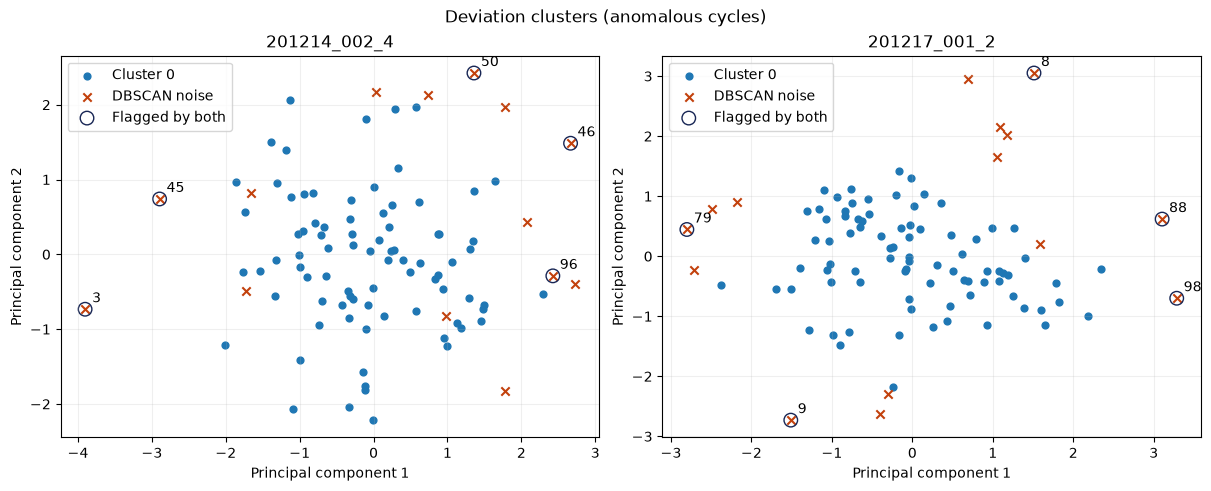

In [35]:
runs = list(clustered.groupby("run_id"))
fig, axes = plt.subplots(
    1, len(runs), figsize=(6 * len(runs), 4.8),
    squeeze=False, layout="constrained",
)

for ax, (run_id, run) in zip(axes[0], runs):
    clusters = run.loc[~run["dbscan_noise"]]
    noise = run.loc[run["dbscan_noise"]]
    both = run.loc[run["flagged_by_both"]]

    for label, group in clusters.groupby("dbscan_label"):
        ax.scatter(group["pc1"], group["pc2"], s=24, label=f"Cluster {label}")

    ax.scatter(
        noise["pc1"], noise["pc2"],
        marker="x", color="#C2410C", label="DBSCAN noise",
    )
    ax.scatter(
        both["pc1"], both["pc2"], s=95, facecolors="none",
        edgecolors="#172554", label="Flagged by both",
    )

    for point in both.itertuples():
        ax.annotate(
            str(point.Cycle_Index), (point.pc1, point.pc2),
            xytext=(5, 5), textcoords="offset points",
        )

    ax.set(
        title=run_id.removeprefix("LR1865SZ_cycles"),
        xlabel="Principal component 1",
        ylabel="Principal component 2",
    )
    ax.grid(alpha=0.2)
    ax.legend()

fig.suptitle("Deviation clusters (anomalous cycles)")

output = Path(
    r"C:\Users\suman\Documents\meatech-battery-analytics-case-study"
) / "results" / "task3_results" / "dbscan_deviation_clusters.png"

fig.savefig(output, dpi=200, bbox_inches="tight")
plt.show()